# Foundermatcha — Objective 2: Funnel & Journey Analysis

**What this notebook does:**  
Tracks how many users reach each step of the Foundermatcha process, measures where they drop off,
how long each step takes, and what separates users who convert from those who don't.

**Files needed:** `users_clean.csv`, `matches_clean.csv`, `events_clean.csv` — from Objective 1.


In [1]:
# ── Step 1: Import libraries ─────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded.")

Libraries loaded.


In [2]:
# ── Step 2: Load clean data ──────────────────────────────────────────────
users   = pd.read_csv('../data/users_clean.csv')
matches = pd.read_csv('../data/matches_clean.csv')
events  = pd.read_csv('../data/events_clean.csv')

# Parse dates
users['signup_date']      = pd.to_datetime(users['signup_date'])
events['event_timestamp'] = pd.to_datetime(events['event_timestamp'])

print(f"users:   {len(users):,} rows")
print(f"matches: {len(matches):,} rows")
print(f"events:  {len(events):,} rows")

# Useful sets — users who reached key milestones
intro_users   = set(events[events['event_type'] == 'intro_sent']['user_id'])
meeting_users = set(events[events['event_type'] == 'meeting_booked']['user_id'])
print(f"\nUsers who got an intro sent:   {len(intro_users):,}")
print(f"Users who booked a meeting:    {len(meeting_users):,}")

users:   2,000 rows
matches: 1,917 rows
events:  12,631 rows

Users who got an intro sent:   339
Users who booked a meeting:    278


## Part A — Conversion Funnel

The funnel counts how many *unique users* reached each step.
A user only counts once per stage, even if they triggered that event multiple times.


In [3]:
# ── Step 3: Build the funnel ─────────────────────────────────────────────
funnel_order = [
    'signup', 'email_verified', 'profile_updated', 'match_suggested',
    'match_viewed', 'intro_requested', 'intro_sent', 'meeting_booked'
]

funnel = {}
for stage in funnel_order:
    funnel[stage] = events[events['event_type'] == stage]['user_id'].nunique()

# Print funnel with drop-off rates
print(f"{'Stage':<25} {'Users':>6}  {'Drop to next':>14}  {'Drop %':>7}  {'Overall %':>10}")
print("-" * 70)
prev = None
for s in funnel_order:
    n = funnel[s]
    if prev:
        drop_n   = prev - n
        drop_pct = drop_n / prev * 100
        overall  = n / funnel['signup'] * 100
        print(f"{s:<25} {n:>6}  {drop_n:>14,}  {drop_pct:>6.1f}%  {overall:>9.1f}%")
    else:
        print(f"{s:<25} {n:>6}  {'—':>14}  {'—':>7}  {'100.0%':>10}")
    prev = n

Stage                      Users    Drop to next   Drop %   Overall %
----------------------------------------------------------------------
signup                      2000               —        —      100.0%
email_verified              1842             158     7.9%       92.1%
profile_updated             1401             441    23.9%       70.0%
match_suggested             1114             287    20.5%       55.7%
match_viewed                 974             140    12.6%       48.7%
intro_requested              370             604    62.0%       18.5%
intro_sent                   339              31     8.4%       17.0%
meeting_booked               278              61    18.0%       13.9%


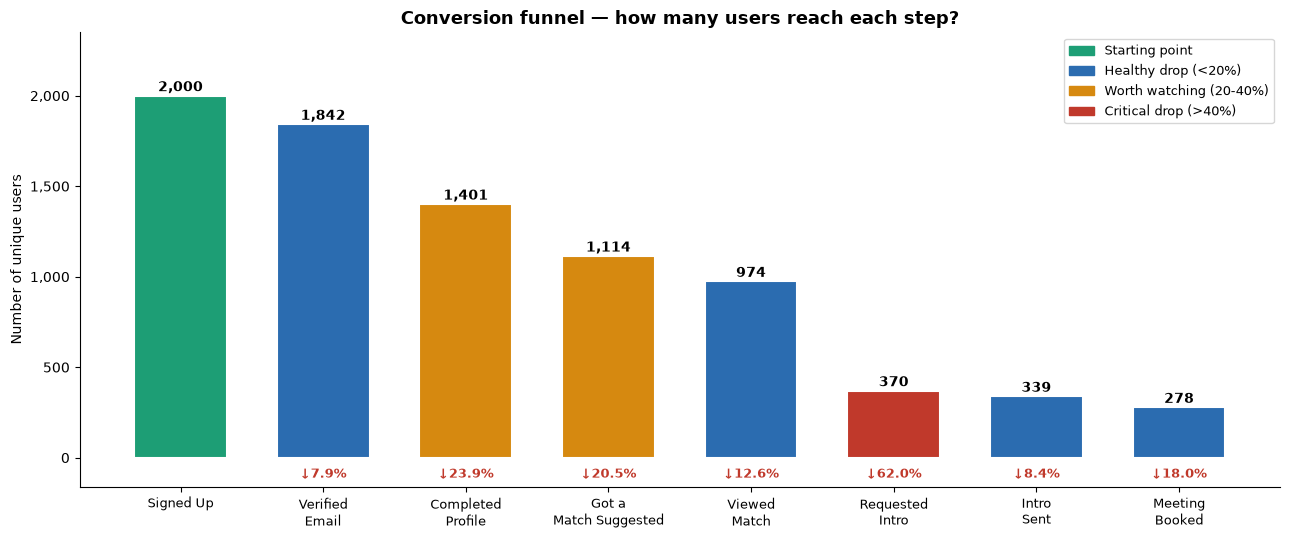

Chart saved as obj2_funnel.png


In [4]:
# ── Step 4: Plot the funnel ──────────────────────────────────────────────
stages = ['Signed Up', 'Verified\nEmail', 'Completed\nProfile', 'Got a\nMatch Suggested',
          'Viewed\nMatch', 'Requested\nIntro', 'Intro\nSent', 'Meeting\nBooked']
vals   = [funnel[s] for s in funnel_order]
drops  = [None, 7.9, 23.9, 20.5, 12.6, 62.0, 8.4, 18.0]

BLUE='#2B6CB0'; TEAL='#1D9E75'; CORAL='#C0392B'; AMBER='#D68910'
clrs = [TEAL if not d else CORAL if d >= 40 else AMBER if d >= 20 else BLUE for d in drops]

fig, ax = plt.subplots(figsize=(13, 5.5))
x = range(len(stages))
bars = ax.bar(x, vals, color=clrs, width=0.65, edgecolor='white', linewidth=1.5)

for bar, v, d in zip(bars, vals, drops):
    ax.text(bar.get_x() + bar.get_width()/2, v + 25,
            f'{v:,}', ha='center', fontsize=10, fontweight='bold')
    if d:
        ax.text(bar.get_x() + bar.get_width()/2, -110,
                f'↓{d}%', ha='center', fontsize=9, color='#C0392B', fontweight='bold')

ax.set_xticks(list(x))
ax.set_xticklabels(stages, fontsize=9.5)
ax.set_ylabel('Number of unique users')
ax.set_title('Conversion funnel — how many users reach each step?',
             fontweight='bold', fontsize=13)
ax.set_ylim(-160, 2350)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v,_: f'{int(v):,}' if v >= 0 else ''))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

patches = [mpatches.Patch(color=TEAL,  label='Starting point'),
           mpatches.Patch(color=BLUE,  label='Healthy drop (<20%)'),
           mpatches.Patch(color=AMBER, label='Worth watching (20-40%)'),
           mpatches.Patch(color=CORAL, label='Critical drop (>40%)')]
ax.legend(handles=patches, loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig('obj2_funnel.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved as obj2_funnel.png")

### Key funnel findings

| Stage transition | Drop-off | What it means |
|---|---|---|
| Signup → Email verified | **7.9%** — healthy | Most users verify quickly |
| Email → Profile completed | **23.9%** — needs attention | 1 in 4 never finishes their profile |
| Profile → Match suggested | **20.5%** — needs attention | Platform takes time to find matches |
| Match suggested → Match viewed | **12.6%** — healthy | Most users do look at their match |
| **Match viewed → Intro requested** | **62.0% — CRITICAL** | The biggest problem in the whole funnel |
| Intro requested → Intro sent | **8.4%** — healthy | Once requested, intros usually go out |
| Intro sent → Meeting booked | **18.0%** — monitor | 1 in 5 intros does not lead to a meeting |

**The single biggest finding:** 604 users looked at a match but never requested an introduction.
That is the platform's #1 conversion problem.


## Part B — Time Between Steps

How long does it take a user to move from one step to the next?
We use each user's *first* timestamp for each event type, then measure the gap in days.


In [5]:
# ── Step 5: Calculate time between stages ────────────────────────────────
# Get the first time each user triggered each event type
first_event = (events
    .groupby(['user_id', 'event_type'])['event_timestamp']
    .min()
    .reset_index()
    .rename(columns={'event_timestamp': 'first_ts'})
)

stage_pairs = [
    ('signup',         'email_verified'),
    ('email_verified', 'profile_updated'),
    ('profile_updated','match_suggested'),
    ('match_suggested','match_viewed'),
    ('match_viewed',   'intro_requested'),
    ('intro_requested','intro_sent'),
    ('intro_sent',     'meeting_booked'),
]

print(f"{'Step transition':<45} {'Median':>8} {'Mean':>8} {'Q1':>6} {'Q3':>6} {'n':>5}")
print("-" * 80)

timing_results = []
for s1, s2 in stage_pairs:
    t1 = first_event[first_event['event_type']==s1][['user_id','first_ts']].rename(columns={'first_ts':'t1'})
    t2 = first_event[first_event['event_type']==s2][['user_id','first_ts']].rename(columns={'first_ts':'t2'})
    merged = t1.merge(t2, on='user_id')
    merged['days'] = (merged['t2'] - merged['t1']).dt.total_seconds() / 86400
    merged = merged[merged['days'] >= 0]
    med = merged['days'].median()
    avg = merged['days'].mean()
    q1  = merged['days'].quantile(0.25)
    q3  = merged['days'].quantile(0.75)
    n   = len(merged)
    timing_results.append({'from':s1,'to':s2,'median':med,'mean':avg,'q1':q1,'q3':q3,'n':n})
    label = f"{s1} → {s2}"
    print(f"{label:<45} {med:>7.1f}d {avg:>7.1f}d {q1:>5.1f}d {q3:>5.1f}d {n:>5}")

Step transition                                 Median     Mean     Q1     Q3     n
--------------------------------------------------------------------------------
signup → email_verified                           1.0d     1.0d   0.5d   1.5d  1842
email_verified → profile_updated                  2.8d     2.8d   1.4d   4.2d  1190
profile_updated → match_suggested                21.0d    55.8d   6.0d  87.0d   961
match_suggested → match_viewed                    2.0d    10.1d   1.0d   4.0d   965
match_viewed → intro_requested                    4.0d     5.6d   1.0d   8.0d   314
intro_requested → intro_sent                      2.0d     3.0d   1.0d   4.0d   240
intro_sent → meeting_booked                       8.0d     8.7d   4.0d  12.0d   244


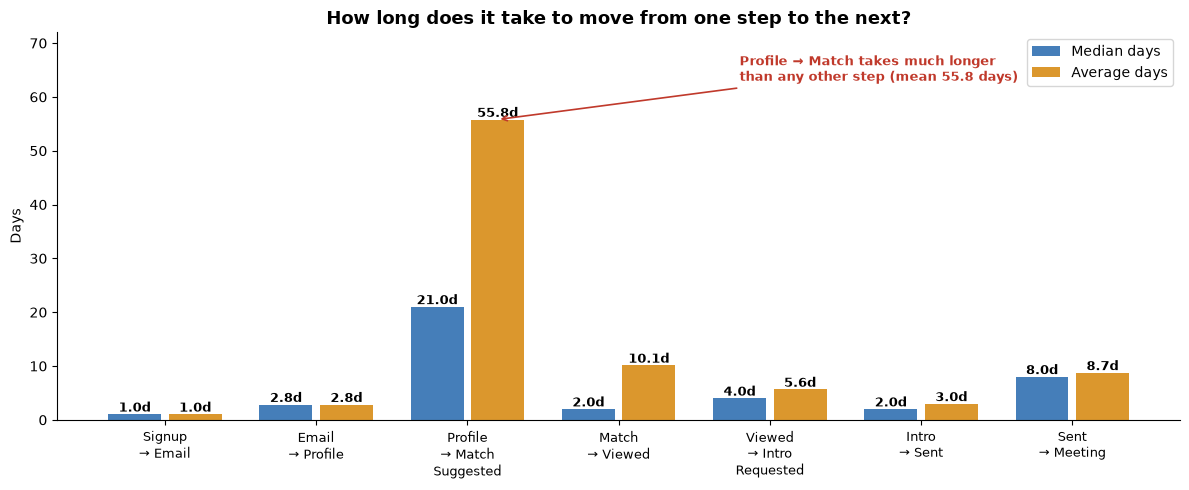

Chart saved as obj2_timing.png


In [6]:
# ── Step 6: Plot timing chart ────────────────────────────────────────────
pair_labels = ['Signup\n→ Email','Email\n→ Profile','Profile\n→ Match\nSuggested',
               'Match\n→ Viewed','Viewed\n→ Intro\nRequested','Intro\n→ Sent','Sent\n→ Meeting']
medians = [r['median'] for r in timing_results]
means   = [r['mean']   for r in timing_results]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(pair_labels))
b1 = ax.bar(x - 0.2, medians, 0.35, label='Median days', color='#2B6CB0', alpha=0.88)
b2 = ax.bar(x + 0.2, means,   0.35, label='Average days', color='#D68910', alpha=0.88)

for bar, v in zip(b1, medians):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{v:.1f}d', ha='center', fontsize=9, fontweight='bold')
for bar, v in zip(b2, means):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{v:.1f}d', ha='center', fontsize=9, fontweight='bold')

ax.set_xticks(x); ax.set_xticklabels(pair_labels, fontsize=9.5)
ax.set_ylabel('Days')
ax.set_title('How long does it take to move from one step to the next?',
             fontweight='bold', fontsize=13)
ax.set_ylim(0, 72); ax.legend(fontsize=10)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.annotate('Profile → Match takes much longer\nthan any other step (mean 55.8 days)',
            xy=(2.2, 55.8), xytext=(3.8, 63), fontsize=9, color='#C0392B', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#C0392B', lw=1.2))
plt.tight_layout()
plt.savefig('obj2_timing.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved as obj2_timing.png")

### Key timing findings

- **Signup → Email verified: 1 day** — users who sign up are motivated and verify quickly.
- **Email → Profile completed: 2.8 days** — also fast; the problem is not slowness, it is that 441 users never do it at all.
- **Profile → Match suggested: median 21 days, mean 55.8 days** — the huge gap between median and mean means a small group waits months for a match. This suggests the matching engine struggles to find pairings for some users.
- **Match viewed → Intro requested: 4 days** — among the users who *do* request an intro, they tend to decide within a week. The 62% who never request simply disengage rather than thinking slowly.
- **Intro sent → Meeting booked: 8 days** — a typical working week and a half to agree on a meeting time.


## Part C — Founders vs Engineers

The platform works differently for the two user types.
Introductions are *only* ever requested by founders — engineers cannot initiate them.


In [7]:
# ── Step 7: Split funnel by user type ────────────────────────────────────
for utype in ['founder', 'engineer']:
    uids = set(users[users['user_type'] == utype]['user_id'])
    total = len(uids)
    print(f"\n{utype.upper()} (n={total:,})")
    print(f"{'Stage':<25} {'Users':>6}  {'% of this type':>15}")
    print("-" * 48)
    for s in funnel_order:
        n   = events[(events['event_type']==s) & (events['user_id'].isin(uids))]['user_id'].nunique()
        pct = n / total * 100
        print(f"  {s:<23} {n:>6}  {pct:>14.1f}%")


FOUNDER (n=789)
Stage                      Users   % of this type
------------------------------------------------
  signup                     767            97.2%
  email_verified             710            90.0%
  profile_updated            526            66.7%
  match_suggested            526            66.7%
  match_viewed               476            60.3%
  intro_requested            359            45.5%
  intro_sent                 329            41.7%
  meeting_booked             270            34.2%

ENGINEER (n=1,211)
Stage                      Users   % of this type
------------------------------------------------
  signup                    1174            96.9%
  email_verified            1078            89.0%
  profile_updated            837            69.1%
  match_suggested            557            46.0%
  match_viewed               471            38.9%
  intro_requested              0             0.0%
  intro_sent                   0             0.0%
  meeting_booke

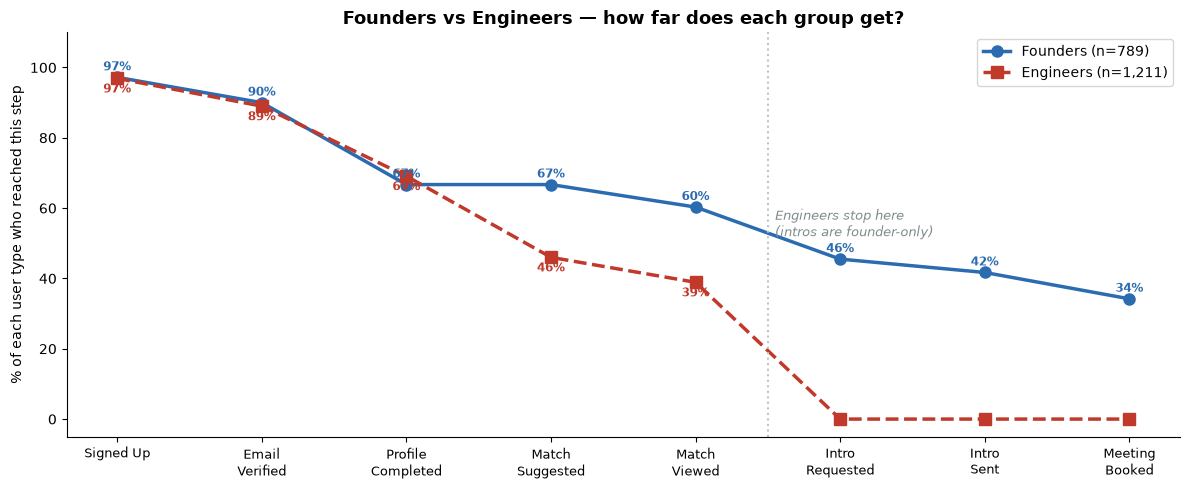

In [8]:
# ── Step 8: Plot founder vs engineer funnel ──────────────────────────────
stages_fe = ['Signed Up','Email\nVerified','Profile\nCompleted','Match\nSuggested',
             'Match\nViewed','Intro\nRequested','Intro\nSent','Meeting\nBooked']
f_pct = [97.2, 90.0, 66.7, 66.7, 60.3, 45.5, 41.7, 34.2]
e_pct = [96.9, 89.0, 69.1, 46.0, 38.9, 0,    0,    0   ]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(stages_fe))
ax.plot(x, f_pct, 'o-', color='#2B6CB0', lw=2.5, ms=8, label='Founders (n=789)')
ax.plot(x, e_pct, 's--',color='#C0392B', lw=2.5, ms=8, label='Engineers (n=1,211)')
for i, (fp, ep) in enumerate(zip(f_pct, e_pct)):
    ax.text(i, fp+2, f'{fp:.0f}%', ha='center', fontsize=8.5, color='#2B6CB0', fontweight='bold')
    if ep > 0:
        ax.text(i, ep-4, f'{ep:.0f}%', ha='center', fontsize=8.5, color='#C0392B', fontweight='bold')

ax.axvline(4.5, color='#BDC3C7', linestyle=':', lw=1.5)
ax.text(4.55, 52, 'Engineers stop here\n(intros are founder-only)', fontsize=9, color='#7F8C8D', style='italic')
ax.set_xticks(x); ax.set_xticklabels(stages_fe, fontsize=9.5)
ax.set_ylabel('% of each user type who reached this step')
ax.set_title('Founders vs Engineers — how far does each group get?', fontweight='bold', fontsize=13)
ax.legend(fontsize=10); ax.set_ylim(-5, 110)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj2_usertype.png', dpi=150, bbox_inches='tight')
plt.show()

### Key founder vs engineer findings

- Both types sign up and verify at similar rates (~97% and ~90%).
- Engineers are slightly *better* at completing their profile (69.1% vs 66.7% of founders).
- Engineers fall behind at **match suggested** — only 46% vs 66.7% of founders. The matching engine surfaces fewer matches per engineer than per founder.
- Engineers record zero intro requests, intro sends, and meeting bookings — this is correct by design. Introductions are started by founders only.


## Part D — Cohort Analysis

A cohort is a group of users who all signed up in the same month.
We check whether the month someone joined affects how likely they are to convert.


In [9]:
# ── Step 9: Cohort analysis ───────────────────────────────────────────────
users['signup_month'] = users['signup_date'].dt.to_period('M')

cohort = (users
    .groupby('signup_month')
    .agg(
        total          = ('user_id', 'count'),
        reached_intro  = ('user_id', lambda x: x.isin(intro_users).sum()),
        reached_meeting= ('user_id', lambda x: x.isin(meeting_users).sum()),
    )
    .reset_index()
)
cohort['intro_rate']   = (cohort['reached_intro']   / cohort['total'] * 100).round(1)
cohort['meeting_rate'] = (cohort['reached_meeting'] / cohort['total'] * 100).round(1)

print(cohort[['signup_month','total','reached_intro','intro_rate','reached_meeting','meeting_rate']].to_string(index=False))

signup_month  total  reached_intro  intro_rate  reached_meeting  meeting_rate
     2025-05    166             23        13.9               18          10.8
     2025-06    171             30        17.5               23          13.5
     2025-07    165             17        10.3               13           7.9
     2025-08    195             28        14.4               26          13.3
     2025-09    166             23        13.9               21          12.7
     2025-10    160             29        18.1               25          15.6
     2025-11    179             26        14.5               17           9.5
     2025-12    151             25        16.6               21          13.9
     2026-01    166             24        14.5               18          10.8
     2026-02    151             37        24.5               33          21.9
     2026-03    166             42        25.3               33          19.9
     2026-04    164             25        15.2               22 

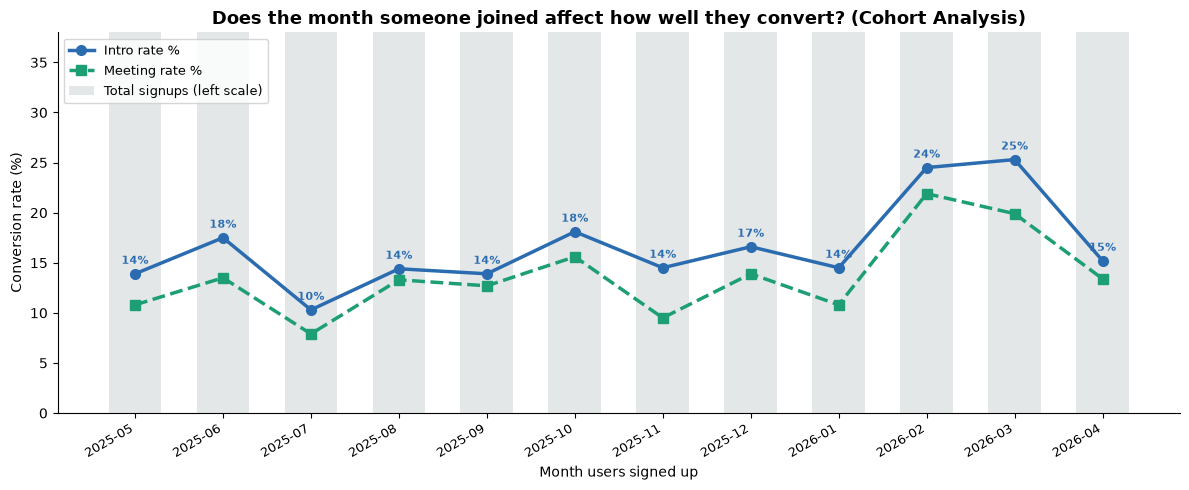

In [10]:
# ── Step 10: Plot cohort conversion ──────────────────────────────────────
months = [str(m) for m in cohort['signup_month']]
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(months, cohort['total'], color='#BDC3C7', alpha=0.4, width=0.6, label='Total signups (left scale)')
ax.plot(months, cohort['intro_rate'],   'o-', color='#2B6CB0', lw=2.5, ms=7, label='Intro rate %')
ax.plot(months, cohort['meeting_rate'],'s--', color='#1D9E75', lw=2.5, ms=7, label='Meeting rate %')
for i, (ir, mr) in enumerate(zip(cohort['intro_rate'], cohort['meeting_rate'])):
    ax.text(i, ir + 1, f'{ir:.0f}%', ha='center', fontsize=8, color='#2B6CB0', fontweight='bold')
ax.set_ylim(0, 38)
ax.set_ylabel('Conversion rate (%)')
ax.set_xlabel('Month users signed up')
ax.set_title('Does the month someone joined affect how well they convert? (Cohort Analysis)',
             fontweight='bold', fontsize=13)
ax.legend(loc='upper left', fontsize=9)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.tight_layout()
plt.savefig('obj2_cohort.png', dpi=150, bbox_inches='tight')
plt.show()

### Key cohort findings

- The **Feb 2026 and Mar 2026 cohorts** convert at 24.5% and 25.3% respectively — roughly double the rate of most earlier cohorts.
- Earlier cohorts (May–Aug 2025) tend to convert between 10–15%.
- The improvement in later cohorts could mean the platform has improved over time (better matching, better user experience), or that it is now attracting a different type of user.
- **No cohort converts below 7.9%** — the platform is consistently generating *some* value across all periods.


## Part E — Speed Analysis

Does it matter *how quickly* a user views their first match?
We split users into fast (within 21 days of signing up) and slow (took longer).


In [11]:
# ── Step 11: Speed to first match view ───────────────────────────────────
t_signup = first_event[first_event['event_type']=='signup'][['user_id','first_ts']].rename(columns={'first_ts':'t_signup'})
t_viewed = first_event[first_event['event_type']=='match_viewed'][['user_id','first_ts']].rename(columns={'first_ts':'t_viewed'})

speed = t_signup.merge(t_viewed, on='user_id')
speed['days_to_view'] = (speed['t_viewed'] - speed['t_signup']).dt.total_seconds() / 86400
speed = speed[speed['days_to_view'] >= 0]
speed['converted'] = speed['user_id'].isin(intro_users)

median_view = speed['days_to_view'].median()
print(f"Median days from sign-up to first match view: {median_view:.1f} days")

fast = speed[speed['days_to_view'] <= median_view]
slow = speed[speed['days_to_view'] >  median_view]

print(f"\nFast viewers  (≤{median_view:.0f} days): {len(fast):,} users — intro conversion rate: {fast['converted'].mean()*100:.1f}%")
print(f"Slow viewers  (>{median_view:.0f} days): {len(slow):,} users — intro conversion rate: {slow['converted'].mean()*100:.1f}%")
print(f"\nFast viewers are {fast['converted'].mean()/slow['converted'].mean():.1f}x more likely to convert than slow viewers.")

Median days from sign-up to first match view: 21.0 days

Fast viewers  (≤21 days): 493 users — intro conversion rate: 61.7%
Slow viewers  (>21 days): 481 users — intro conversion rate: 7.3%

Fast viewers are 8.5x more likely to convert than slow viewers.


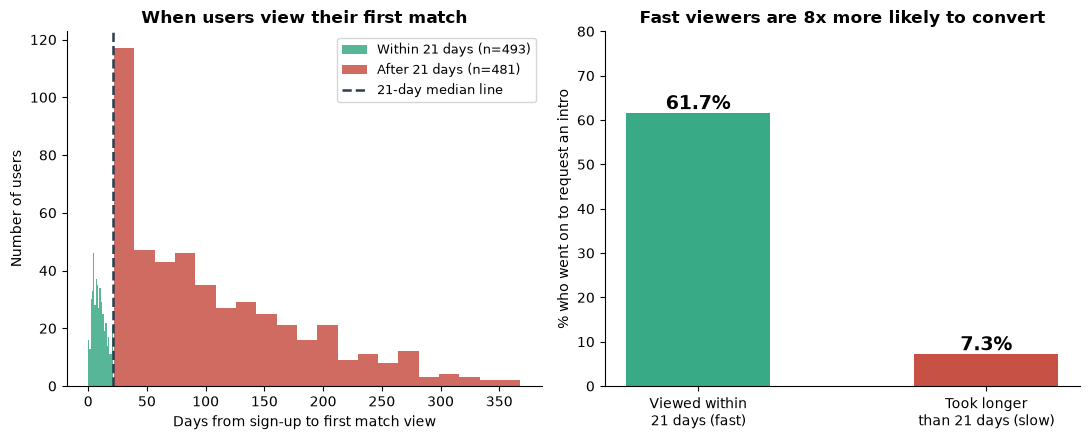

In [12]:
# ── Step 12: Plot speed vs conversion ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Distribution
axes[0].hist(fast['days_to_view'], bins=20, color='#1D9E75', alpha=0.75,
             label=f'Within 21 days (n={len(fast):,})')
axes[0].hist(slow['days_to_view'], bins=20, color='#C0392B', alpha=0.75,
             label=f'After 21 days (n={len(slow):,})')
axes[0].axvline(median_view, color='#2C3E50', linestyle='--', lw=1.8, label='21-day median line')
axes[0].set_xlabel('Days from sign-up to first match view')
axes[0].set_ylabel('Number of users')
axes[0].set_title('When users view their first match', fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

# Conversion rate
groups = ['Viewed within\n21 days (fast)', 'Took longer\nthan 21 days (slow)']
rates  = [fast['converted'].mean()*100, slow['converted'].mean()*100]
colors = ['#1D9E75', '#C0392B']
bars = axes[1].bar(groups, rates, color=colors, width=0.5, alpha=0.88)
for bar, v in zip(bars, rates):
    axes[1].text(bar.get_x()+bar.get_width()/2, v+0.8,
                 f'{v:.1f}%', ha='center', fontsize=14, fontweight='bold')
axes[1].set_ylabel('% who went on to request an intro')
axes[1].set_title('Fast viewers are 8x more likely to convert', fontweight='bold')
axes[1].set_ylim(0, 80)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj2_speed.png', dpi=150, bbox_inches='tight')
plt.show()

### Key speed finding

Users who view their first match **within 21 days** of signing up convert at **61.7%**.  
Users who take **longer than 21 days** convert at just **7.3%**.

That is an **8x difference**. This is the strongest single predictor of conversion found so far
and has a clear action: get users to their first match as quickly as possible after they sign up.


## Part F — Session Behaviour

Do users who convert come back to the platform more often?
Session number tracks how many separate visits a user made.


In [13]:
# ── Step 13: Session analysis ─────────────────────────────────────────────
sessions = (events
    .groupby('user_id')['session_number']
    .max()
    .reset_index()
    .rename(columns={'session_number':'max_sessions'})
)
sessions['converted'] = sessions['user_id'].isin(intro_users)

conv   = sessions[sessions['converted']]
noconv = sessions[~sessions['converted']]

print("SESSIONS — converted users vs non-converted:")
print(f"  Converted   — median: {conv['max_sessions'].median():.1f}  mean: {conv['max_sessions'].mean():.1f}")
print(f"  Not converted — median: {noconv['max_sessions'].median():.1f}  mean: {noconv['max_sessions'].mean():.1f}")
print(f"\nConverted users log back in {conv['max_sessions'].median()/noconv['max_sessions'].median():.1f}x more often (median sessions).")

SESSIONS — converted users vs non-converted:
  Converted   — median: 5.0  mean: 4.8
  Not converted — median: 2.0  mean: 2.5

Converted users log back in 2.5x more often (median sessions).


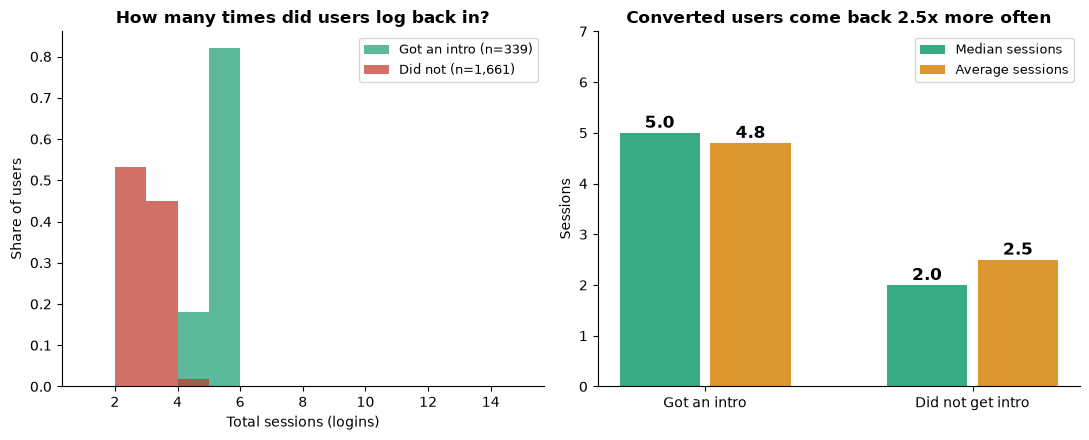

In [14]:
# ── Step 14: Plot sessions ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(conv['max_sessions'],   bins=range(1,16), alpha=0.72,
             color='#1D9E75', label=f'Got an intro (n={len(conv):,})', density=True)
axes[0].hist(noconv['max_sessions'], bins=range(1,16), alpha=0.72,
             color='#C0392B', label=f'Did not (n={len(noconv):,})', density=True)
axes[0].set_xlabel('Total sessions (logins)')
axes[0].set_ylabel('Share of users')
axes[0].set_title('How many times did users log back in?', fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

x2 = np.arange(2)
axes[1].bar(x2-0.17, [5.0, 2.0], 0.3, label='Median sessions', color='#1D9E75', alpha=0.88)
axes[1].bar(x2+0.17, [4.8, 2.5], 0.3, label='Average sessions', color='#D68910', alpha=0.88)
for i, (m, a) in enumerate(zip([5.0, 2.0], [4.8, 2.5])):
    axes[1].text(i-0.17, m+0.1, str(m), ha='center', fontsize=12, fontweight='bold')
    axes[1].text(i+0.17, a+0.1, str(a), ha='center', fontsize=12, fontweight='bold')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(['Got an intro', 'Did not get intro'], fontsize=10)
axes[1].set_ylabel('Sessions')
axes[1].set_title('Converted users come back 2.5x more often', fontweight='bold')
axes[1].legend(fontsize=9); axes[1].set_ylim(0, 7)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj2_sessions.png', dpi=150, bbox_inches='tight')
plt.show()

## Part G — Device and Platform

Device type (excluding 'unknown'):
device_type
desktop    5915
mobile     5449
tablet      618
device_type
desktop    49.4
mobile     45.5
tablet      5.2

Platform (excluding 'unknown'):
platform
web        6602
iOS        3113
Android    2388
platform
web        54.5
iOS        25.7
Android    19.7

Excluded as 'unknown': 649 device, 528 platform


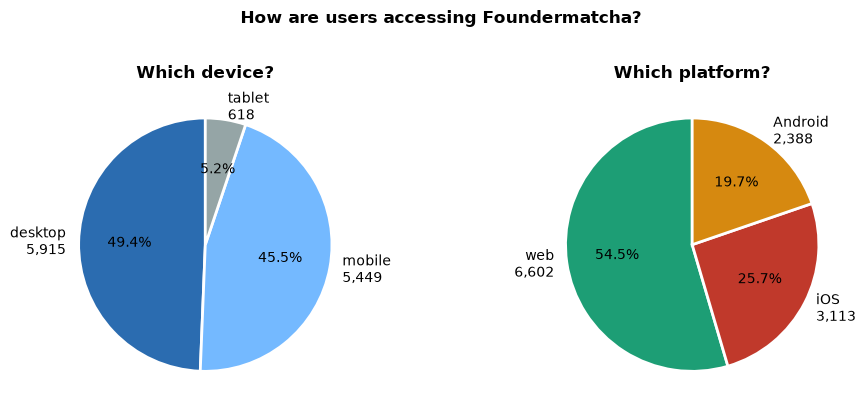

In [15]:
# ── Step 15: Device and platform breakdown ────────────────────────────────
device_data   = events[events['device_type']!='unknown']['device_type'].value_counts()
platform_data = events[events['platform']!='unknown']['platform'].value_counts()

print("Device type (excluding 'unknown'):")
print(device_data.to_string())
print((device_data / device_data.sum() * 100).round(1).to_string())
print("\nPlatform (excluding 'unknown'):")
print(platform_data.to_string())
print((platform_data / platform_data.sum() * 100).round(1).to_string())
print(f"\nExcluded as 'unknown': {(events['device_type']=='unknown').sum()} device, "
      f"{(events['platform']=='unknown').sum()} platform")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].pie(device_data.values,
            labels=[f'{l}\n{v:,}' for l, v in zip(device_data.index, device_data.values)],
            colors=['#2B6CB0','#74B9FF','#95A5A6'], autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('Which device?', fontweight='bold')

axes[1].pie(platform_data.values,
            labels=[f'{l}\n{v:,}' for l, v in zip(platform_data.index, platform_data.values)],
            colors=['#1D9E75','#C0392B','#D68910'], autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Which platform?', fontweight='bold')

plt.suptitle('How are users accessing Foundermatcha?', fontweight='bold', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('obj2_device.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary — All Objective 2 Findings

| Finding | Numbers | Action |
|---|---|---|
| Biggest drop-off: match viewed → intro requested | **62%** (604 users lost) | Nudge users within 48 hrs of viewing a match |
| Profile completion drop-off | **23.9%** (441 users) | Guided onboarding wizard |
| Profile → Match suggested takes longest | Median 21 days, mean 55.8 days | Improve matching speed |
| Fast viewers convert 8x better | 61.7% vs 7.3% | Get users to their first match ASAP |
| Converted users return 2.5x more | Median 5 sessions vs 2 | Re-engagement emails for inactive users |
| Feb–Mar 2026 cohorts convert at 2x the rate | 24.5%–25.3% vs ~13% average | Understand what changed and replicate it |
| Engineers drop at match suggested | 46% vs 66.7% founders | Improve engineer profile prompts |
| Desktop is most used device | 49.4% desktop, 45.5% mobile | Ensure mobile experience is not degraded |


In [16]:
# ── Step 16: Save clean summary table ─────────────────────────────────────
summary = pd.DataFrame({
    'Stage': ['signup','email_verified','profile_updated','match_suggested',
              'match_viewed','intro_requested','intro_sent','meeting_booked'],
    'Unique Users': [2000,1842,1401,1114,974,370,339,278],
    'Drop to Next (#)': [158,441,287,140,604,31,61,'—'],
    'Drop to Next (%)': ['7.9%','23.9%','20.5%','12.6%','62.0%','8.4%','18.0%','—'],
    'Overall Conv %':   ['100%','92.1%','70.0%','55.7%','48.7%','18.5%','17.0%','13.9%'],
})
summary.to_csv('obj2_funnel_summary.csv', index=False)
print("Saved: obj2_funnel_summary.csv")
print(summary.to_string(index=False))

Saved: obj2_funnel_summary.csv
          Stage  Unique Users Drop to Next (#) Drop to Next (%) Overall Conv %
         signup          2000              158             7.9%           100%
 email_verified          1842              441            23.9%          92.1%
profile_updated          1401              287            20.5%          70.0%
match_suggested          1114              140            12.6%          55.7%
   match_viewed           974              604            62.0%          48.7%
intro_requested           370               31             8.4%          18.5%
     intro_sent           339               61            18.0%          17.0%
 meeting_booked           278                —                —          13.9%
